In [2]:
from importlib.metadata import version

pkgs = ['matplotlib',
        'numpy',
        'tiktoken',
        'torch',
        'tensorflow',
        'pandas']

for p in pkgs:
    print(f'{p} version: {version(p)}')

matplotlib version: 3.11.2
numpy version: 2.5.3
tiktoken version: 0.14.0
torch version: 2.14.0
tensorflow version: 2.21.0
pandas version: 3.0.6


In [3]:
import urllib.request
#python内置标准库,处理zip压缩文件
import zipfile
import os
#python内置标准库
#现在的更通用的方法,路径是一个对象了,传统是一个字符
    #免去了os不同/\不同的问题
from pathlib import Path

In [4]:
url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
zip_path = "sms_spam_collection.zip"
extracted_path = "sms_spam_collection"
#把字符包装成了一个对象,用/可以拼接对象
data_file_path = Path(extracted_path) / "SMSSpamCollection.tsv"

In [5]:
def download_and_unzip_spam_data(url,zip_path,extracted_path,data_file_path):
    if data_file_path.exists():
        print(f"{data_file_path} already exists. Skipping download and extraction.")
        return

    #官方返回的也是一个zip包
    with urllib.request.urlopen(url) as response:
        #wb是Write Binary,二进制写入
        with open(zip_path,'wb') as out_file:
            out_file.write(response.read())

    with zipfile.ZipFile(zip_path,'r') as zip_ref:
        zip_ref.extractall(extracted_path)

    original_file_path = Path(extracted_path) / 'SMSSpamCollection'
    os.rename(original_file_path,data_file_path)
    print(f'File downloaded and seved as {data_file_path}')

#文件没有魔数(除了.后的后缀),所以默认当文本读取,.tsv也是没有魔数的,默认是文本约定
    #所以后缀的作用是提示软件用\t分隔符切分
download_and_unzip_spam_data(url,zip_path,extracted_path,data_file_path)

sms_spam_collection/SMSSpamCollection.tsv already exists. Skipping download and extraction.


In [6]:
import pandas as pd
df = pd.read_csv(data_file_path,sep = '\t',header = None,names = ['Label','Text'])
df

,Label,Text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
...,...,...
5567,spam,This is the 2nd time we have tried 2 contact u...
5568,ham,Will ü b going to esplanade fr home?
5569,ham,"Pity, * was in mood for that. So...any other s..."
5570,ham,The guy did some bitching but I acted like i'd...


In [7]:
print(df['Label'].value_counts())

Label
ham     4825
spam     747
Name: count, dtype: int64


In [8]:
def create_balanced_dataset(df):
    num_spam = df[df['Label'] == 'spam'].shape[0]

    #random_state:随机种子
    ham_subset = df[df['Label'] == 'ham'].sample(num_spam,random_state = 123)

    #concat是拼接concatenate
    balanced_df = pd.concat([ham_subset,df[df['Label'] == 'spam']])

    return balanced_df

In [9]:
balanced_df = create_balanced_dataset(df)
print(balanced_df['Label'].value_counts())

Label
ham     747
spam    747
Name: count, dtype: int64


In [10]:
balanced_df['Label'] = balanced_df['Label'].map({'ham':0,'spam':1})

In [11]:
#fraction:比例
def random_split(df,train_frac,validation_frac):
    #打乱整个df
    #frac是比例,这里1是100%,行索引也会一起乱排,需要reset_index恢复,drop丢弃旧索引
    df = df.sample(frac = 1,random_state = 123).reset_index(drop = True)

    train_end = int(len(df) * train_frac)
    validation_end = train_end + int(len(df) * validation_frac)

    train_df = df[:train_end]
    validation_df = df[train_end:validation_end]
    test_df = df[validation_end:]

    return train_df,validation_df,test_df

In [12]:
train_df,validation_df,test_df = random_split(balanced_df,0.7,0.1)

#index控制是否保留行索引
train_df.to_csv('train.csv',index = None)
validation_df.to_csv('validation.csv',index = None)
test_df.to_csv('test.csv',index = None)

In [13]:
import tiktoken

tokenizer = tiktoken.get_encoding('gpt2')
print(tokenizer.encode('<|endoftext|>',allowed_special = {'<|endoftext|>'}))

[50256]


In [14]:
import torch
from torch.utils.data import Dataset

In [15]:
class SpamDataset(Dataset):
    def __init__(self,csv_file,tokenizer,max_length = None,pad_token_id = 50256):
        self.data = pd.read_csv(csv_file)

        self.encoded_texts = [
            tokenizer.encode(text) for text in self.data['Text']
        ]

        if max_length is None:
            self.max_length = self._longest_encoded_length()
        else:
            self.max_length = max_length
            self.encoded_texts = [
                encoded_text[:self.max_length]
                for encoded_text in self.encoded_texts
            ]

        self.encoded_texts = [
            encoded_text + [pad_token_id] * (self.max_length - len(encoded_text))
            for encoded_text in self.encoded_texts
        ]

    def __getitem__(self,index):
        encoded = self.encoded_texts[index]
        label = self.data.iloc[index]['Label']
        return (
            #long是等价于torch.int64类型,统一两种数据类型
            torch.tensor(encoded,dtype = torch.long),
            torch.tensor(label,dtype = torch.long) 
        )

    def __len__(self):
        return len(self.data)

    def _longest_encoded_length(self):
        #从None>>>0 可进行比较
        max_length = 0
        for encoded_text in self.encoded_texts:
            encoded_length = len(encoded_text)
            if encoded_length > max_length:
                max_length = encoded_length
        return max_length

In [16]:
#大语言模型处理120个长度,而不是填充到1024长度的优势:
#用<|endoftext|>的id填到1024会稀释注意力,导致关键信息的注意力下降
#直接用120个词,后面用掩码了,那边的计算注意力依旧为0,不影响原词位置的的注意力
max_length = None

In [17]:
train_dataset = SpamDataset(
    csv_file = 'train.csv',
    max_length = max_length,
    tokenizer = tokenizer
)

print(train_dataset.max_length)

120


In [18]:
val_dataset = SpamDataset(
    csv_file = 'validation.csv',
    max_length = train_dataset.max_length,
    tokenizer = tokenizer
)


test_dataset = SpamDataset(
    csv_file = 'test.csv',
    max_length = train_dataset.max_length,
    tokenizer = tokenizer
)

In [19]:
from torch.utils.data import DataLoader

#进程数量,为0不容易死机  (算完再读取,多进程是算时可以读取准备了)
num_workers = 0
batch_size = 8

torch.manual_seed(123)

train_loader = DataLoader(
    #DataLoader会自动调用train_dataset里面的train_dataset,用index定位提取数据
    dataset = train_dataset,
    batch_size = batch_size,
    #Epoch读取时候把顺序打乱
    #DataLoader可以记录整个数据的数量(用了len),才可这么操作
    shuffle = True,
    num_workers = num_workers,
    drop_last = True,
)

val_loader = DataLoader(
    dataset = val_dataset,
    batch_size = batch_size,
    num_workers = num_workers,
    drop_last = False
)

test_loader = DataLoader(
    dataset = test_dataset,
    batch_size = batch_size,
    num_workers = num_workers,
    drop_last = False
)

In [20]:
print('Train loader:')

for input_batch,target_batch in train_loader:
    pass

print('Input batch dimensions:',input_batch.shape)
print('Label barch dementions:',target_batch.shape)

Train loader:
Input batch dimensions: torch.Size([8, 120])
Label barch dementions: torch.Size([8])


In [22]:
print(f'{len(train_loader)} training batches')
print(f'{len(val_loader)} validation batches')
print(f'{len(test_loader)} test batches')

130 training batches
19 validation batches
38 test batches


In [23]:
CHOOSE_MODEL = "gpt2-small (124M)"
INPUT_PROMPT = "Every effort moves"

BASE_CONFIG = {
    "vocab_size": 50257,     # Vocabulary size
    "context_length": 1024,  # Context length
    "drop_rate": 0.0,        # Dropout rate
    "qkv_bias": True         # Query-key-value bias
}

model_configs = {
    "gpt2-small (124M)": {"emb_dim": 768, "n_layers": 12, "n_heads": 12},
    "gpt2-medium (355M)": {"emb_dim": 1024, "n_layers": 24, "n_heads": 16},
    "gpt2-large (774M)": {"emb_dim": 1280, "n_layers": 36, "n_heads": 20},
    "gpt2-xl (1558M)": {"emb_dim": 1600, "n_layers": 48, "n_heads": 25},
}

#加载对应模型配置
BASE_CONFIG.update(model_configs[CHOOSE_MODEL])

In [24]:
#assert 条件,错误信息
#错误信息的字符串不需要',',因为可以隐式拼接为一个字符串
#加了()就可以不需要\的换行
assert train_dataset.max_length <= BASE_CONFIG["context_length"], (
    f"Dataset length {train_dataset.max_length} exceeds model's context "
    f"length {BASE_CONFIG['context_length']}. Reinitialize data sets with "
    f"`max_length={BASE_CONFIG['context_length']}`"
)

In [28]:
from gpt_download import download_and_load_gpt2
from previous_chapters import GPTModel, load_weights_into_gpt

#按空格切分,取出最后的元素,去掉左右的(),openai只需要124M这几个字作为参数
model_size = CHOOSE_MODEL.split(" ")[-1].lstrip("(").rstrip(")")
settings, params = download_and_load_gpt2(model_size=model_size, models_dir="gpt2")

model = GPTModel(BASE_CONFIG)
load_weights_into_gpt(model, params)
model.eval();

File already exists and is up-to-date: gpt2/124M/checkpoint
File already exists and is up-to-date: gpt2/124M/encoder.json
File already exists and is up-to-date: gpt2/124M/hparams.json
File already exists and is up-to-date: gpt2/124M/model.ckpt.data-00000-of-00001
File already exists and is up-to-date: gpt2/124M/model.ckpt.index
File already exists and is up-to-date: gpt2/124M/model.ckpt.meta
File already exists and is up-to-date: gpt2/124M/vocab.bpe


In [29]:
from previous_chapters import (
    generate_text_simple,
    text_to_token_ids,
    token_ids_to_text
)

In [30]:
text_1 = "Every effort moves you"

token_ids = generate_text_simple(
    model = model,
    idx = text_to_token_ids(text_1,tokenizer),
    max_new_tokens = 15,
    context_size = BASE_CONFIG['context_length']
)

print(token_ids_to_text(token_ids,tokenizer))

Every effort moves you forward.

The first step is to understand the importance of your work


In [32]:
text_2 = (
    "Is the following text 'spam'? Answer with 'yes' or 'no':"
    " 'You are a winner you have been specially"
    " selected to receive $1000 cash or a $2000 award.'"
)

token_ids = generate_text_simple(
    model = model,
    idx = text_to_token_ids(text_2,tokenizer),
    max_new_tokens = 23,
    context_size = BASE_CONFIG['context_length']
)

print(token_ids_to_text(token_ids,tokenizer))

Is the following text 'spam'? Answer with 'yes' or 'no': 'You are a winner you have been specially selected to receive $1000 cash or a $2000 award.'

The following text 'spam'? Answer with 'yes' or 'no': 'You are a winner


In [33]:
print(model)

GPTModel(
  (tok_emb): Embedding(50257, 768)
  (pos_emb): Embedding(1024, 768)
  (drop_emb): Dropout(p=0.0, inplace=False)
  (trf_blocks): Sequential(
    (0): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=768, out_features=768, bias=True)
        (W_key): Linear(in_features=768, out_features=768, bias=True)
        (W_value): Linear(in_features=768, out_features=768, bias=True)
        (out_proj): Linear(in_features=768, out_features=768, bias=True)
        (dropout): Dropout(p=0.0, inplace=False)
      )
      (ff): FeedForward(
        (layers): Sequential(
          (0): Linear(in_features=768, out_features=3072, bias=True)
          (1): GELU()
          (2): Linear(in_features=3072, out_features=768, bias=True)
        )
      )
      (norm1): LayerNorm()
      (norm2): LayerNorm()
      (drop_resid): Dropout(p=0.0, inplace=False)
    )
    (1): TransformerBlock(
      (att): MultiHeadAttention(
        (W_query): Linear(in_features=768,

In [39]:
#进制所有层训练
#这个.parameters是继承了pytorch的model的语法,可以直接调用所有的参数
for param in model.parameters():
    param.requires_grad = False

In [40]:
torch.manual_seed(123)

#替换out层
num_classes = 2
#requires_grad默认为True,所以这个新的覆盖了的层可以训练
model.out_head = torch.nn.Linear(in_features = BASE_CONFIG['emb_dim'],
                                 out_features = num_classes)

In [42]:
#允许最后一个trf可以训练
#trf_blocks是一个列表,之前GPTModel定义的
for param in model.trf_blocks[-1].parameters():
    param.requires_grad = True

#最终归一化层也可训练
    #注意这不是trf里面的归一化层
#缩放因子和平移偏置可以训练
for param in model.final_norm.parameters():
    param.requires_grad = True

In [44]:
inputs = tokenizer.encode('Do you have time')
#unsqueeze添加一个维度,在指定的维度,用于模拟批处理,位置数字是添加之后的维度所在的位置
inputs = torch.tensor(inputs).unsqueeze(0)
print('Inputs:',inputs)
print('Inputs dimensions:',inputs.shape)

Inputs: tensor([[5211,  345,  423,  640]])
Inputs dimensions: torch.Size([1, 4])


In [47]:
with torch.no_grad():
    outputs = model(inputs)

print('Outputs: \n',outputs)
print('Outputs dimentions:',outputs.shape)

Outputs: 
 tensor([[[-1.5854,  0.9904],
         [-3.7235,  7.4548],
         [-2.2661,  6.6049],
         [-3.5983,  3.9902]]])
Outputs dimentions: torch.Size([1, 4, 2])


In [48]:
print('Last output token:',outputs[:,-1,:])

Last output token: tensor([[-3.5983,  3.9902]])


In [49]:
print('Last output token:',outputs[:,-1,:])

Last output token: tensor([[-3.5983,  3.9902]])


In [50]:
probas = torch.softmax(outputs[:,-1,:],dim = -1)
#如果不指定,argmax会自动降低维度
label = torch.argmax(probas)
print('Class label:',label.item())

Class label: 1


In [53]:
def calc_accuracy_loader(data_loader, model, device, num_batches=None):
    model.eval()
    correct_predictions, num_examples = 0, 0

    if num_batches is None:
        #提取总批次
        num_batches = len(data_loader)
    else:
        #确保是可提取批次,极限是总批次大小
        num_batches = min(num_batches, len(data_loader))
    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i < num_batches:
            input_batch, target_batch = input_batch.to(device), target_batch.to(device)

            with torch.no_grad():
                #输出最后一个词元
                logits = model(input_batch)[:, -1, :]
            #取出最大索引
            predicted_labels = torch.argmax(logits, dim=-1)

            #计数
            num_examples += predicted_labels.shape[0]
            #计算正确数
            correct_predictions += (predicted_labels == target_batch).sum().item()
        else:
            break
    return correct_predictions / num_examples

In [69]:
device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
model.to(device)

torch.manual_seed(123)

train_accuracy = calc_accuracy_loader(train_loader,model,device,num_batches = 10)
val_accuracy = calc_accuracy_loader(val_loader,model,device,num_batches = 10)
test_accuracy = calc_accuracy_loader(test_loader,model,device,num_batches = 10)

print(f'Training accuracy: {train_accuracy * 100:.2f}%')
print(f'Validation accuracy: {val_accuracy * 100:.2f}%')
print(f'Test accuracy: {test_accuracy * 100:.2f}%')

Training accuracy: 46.25%
Validation accuracy: 45.00%
Test accuracy: 48.75%


In [70]:
def calc_loss_batch(input_batch, target_batch, model, device):
    input_batch, target_batch = input_batch.to(device), target_batch.to(device)
    logits = model(input_batch)[:, -1, :]
    loss = torch.nn.functional.cross_entropy(logits, target_batch)
    return loss

In [71]:
def calc_loss_loader(data_loader,model,device,num_batches = None):
    total_loss = 0.
    if len(data_loader) == 0:
        return float('nan')
    elif num_batches is None:
        num_batches = len(data_loader)
    else:
        num_batches = min(num_batches,len(data_loader))

    for i,(input_batch,target_batch) in enumerate(data_loader):
        if i<num_batches:
            loss = calc_loss_batch(input_batch,target_batch,model,device)
            total_loss += loss.item()
        else:
            break
    return total_loss / num_batches

In [72]:
with torch.no_grad():
    train_loss = calc_loss_loader(train_loader,model,device,num_batches = 5)
    val_loss = calc_loss_loader(val_loader,model,device,num_batches = 5)
    test_loss = calc_loss_loader(test_loader,model,device,num_batches = 5)

print(f'Training loss: {train_loss:.3f}')
print(f'Validation loss: {val_loss:.3f}')
print(f'Test loss: {test_loss:.3f}')

Training loss: 2.453
Validation loss: 2.583
Test loss: 2.322


In [79]:
def train_classifier_simple(model,train_loader,val_loader,optimizer,device,num_epochs,
                            eval_freq,eval_iter):
    train_losses,val_losses,train_accs,val_accs = [],[],[],[]
    examples_seen,global_step = 0,-1

    for epoch in range(num_epochs):
        model.train()

        for input_batch,target_batch in train_loader:
            optimizer.zero_grad()
            loss = calc_loss_batch(input_batch,target_batch,model,device)
            loss.backward()
            optimizer.step()
            #计算读取的
            examples_seen += input_batch.shape[0]
            #计算参数批次更新次数
            global_step += 1

            if global_step % eval_freq == 0:
                train_loss,val_loss = evaluate_model(
                    model,train_loader,val_loader,device,eval_iter)
                train_losses.append(train_loss)
                val_losses.append(val_loss)
                #:06d 6位10进制整数,0表示前面补0
                print(f'Ep{epoch + 1} (Step {global_step:06d}): '
                      f'Train loss {train_loss:.3f} , Val loss {val_loss:.3f}')

        #num_batched是直接截取前面这么多的批次
        train_accuracy = calc_accuracy_loader(train_loader,model,device,num_batches = eval_iter)
        val_accuracy = calc_accuracy_loader(val_loader,model,device,num_batches = eval_iter)
        #默认的end是\n,这里不需要换行,保留在原地
        print(f'Training accuracy: {train_accuracy*100:.2f}% | ',end = '')
        print(f'Validation accuracy: {val_accuracy*100:.2f}%')
        train_accs.append(train_accuracy)
        val_accs.append(val_accuracy)

    return train_losses,val_losses,train_accs,val_accs,examples_seen

In [80]:
def evaluate_model(model, train_loader, val_loader, device, eval_iter):
    model.eval()
    with torch.no_grad():
        train_loss = calc_loss_loader(train_loader, model, device, num_batches=eval_iter)
        val_loss = calc_loss_loader(val_loader, model, device, num_batches=eval_iter)
    model.train()
    return train_loss, val_loss

In [81]:
import time
#输出距离1970.1.1的0:00时间的秒数
start_time = time.time()
torch.manual_seed(123)

optimizer = torch.optim.AdamW(model.parameters(),lr = 5e-5,weight_decay = 0.1)

num_epochs = 5

train_losses,val_losses,train_accs,val_accs,examples_seen = train_classifier_simple(
    model,train_loader,val_loader,optimizer,device,
    num_epochs = num_epochs,eval_freq = 50,eval_iter = 5,
)

end_time = time.time()
execution_time_minutes = (end_time - start_time) / 60

print(f'Training completed in {execution_time_minutes:.2f} minutes.')

Ep1 (Step 000000): Train loss 2.153 , Val loss 2.392
Ep1 (Step 000050): Train loss 0.617 , Val loss 0.637
Ep1 (Step 000100): Train loss 0.523 , Val loss 0.557
Training accuracy: 70.00% | Validation accuracy: 72.50%
Ep2 (Step 000150): Train loss 0.561 , Val loss 0.489
Ep2 (Step 000200): Train loss 0.419 , Val loss 0.397
Ep2 (Step 000250): Train loss 0.409 , Val loss 0.353
Training accuracy: 82.50% | Validation accuracy: 85.00%
Ep3 (Step 000300): Train loss 0.333 , Val loss 0.320
Ep3 (Step 000350): Train loss 0.340 , Val loss 0.306
Training accuracy: 90.00% | Validation accuracy: 90.00%
Ep4 (Step 000400): Train loss 0.136 , Val loss 0.200
Ep4 (Step 000450): Train loss 0.153 , Val loss 0.132
Ep4 (Step 000500): Train loss 0.222 , Val loss 0.137
Training accuracy: 100.00% | Validation accuracy: 97.50%
Ep5 (Step 000550): Train loss 0.207 , Val loss 0.143
Ep5 (Step 000600): Train loss 0.083 , Val loss 0.074
Training accuracy: 100.00% | Validation accuracy: 97.50%
Training completed in 1.00 mi

In [85]:
import matplotlib.pyplot as plt

def plot_values(epochs_seen,examples_seen,train_values,val_values,label = 'loss'):
    fig,ax1 = plt.subplots(figsize = (5,3))

    #x和y的数据数量需要对齐,后面用linspace
    ax1.plot(epochs_seen,train_values,label = f'Training {label}')
    ax1.plot(epochs_seen,val_values,linestyle = '-.',label = f'Validation {label}')
    ax1.set_xlabel('Epoches')
    #首字母大写
    ax1.set_ylabel(label.capitalize())
    ax1.legend()

    ax2 = ax1.twiny()
    ax2.plot(examples_seen,train_values,alpha = 0)
    ax2.set_xlabel('Examples seen')

    fig.tight_layout()
    plt.savefig(f'{label}-plot.pdf')
    plt.show()

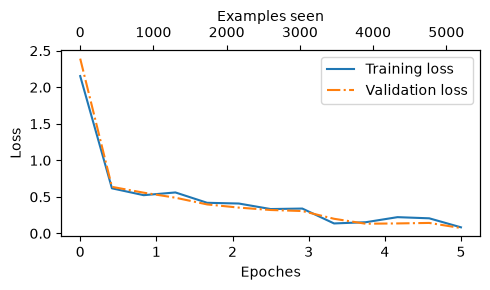

In [87]:
epochs_tensor = torch.linspace(0,num_epochs,len(train_losses))
examples_seen_tensor = torch.linspace(0,examples_seen,len(train_losses))

plot_values(epochs_tensor,examples_seen_tensor,train_losses,val_losses)

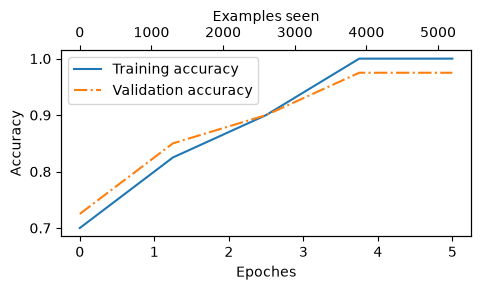

In [89]:
epoch_tensor = torch.linspace(0,num_epochs,len(train_accs))
examples_seen_tensor = torch.linspace(0,examples_seen,len(train_accs))

plot_values(epoch_tensor,examples_seen_tensor,train_accs,val_accs,label = 'accuracy')

In [90]:
train_accracy = calc_accuracy_loader(train_loader,model,device)
val_accuracy = calc_accuracy_loader(val_loader,model,device)
test_accuracy = calc_accuracy_loader(test_loader,model,device)

print(f'train accuracy: {train_accracy*100:.2f}%')
print(f'val accuracy: {val_accuracy*100:.2f}%')
print(f'test accuracy: {test_accuracy*100:.2f}%')

train accuracy: 97.21%
val accuracy: 97.32%
test accuracy: 95.67%


In [92]:
def classify_review(text,model,tokenizer,device,max_length = None,pad_token_id = 50256):
    model.eval()

    input_ids = tokenizer.encode(text)
    supported_context_length = model.pos_emb.weight.shape[1]

    input_ids = input_ids[:min(max_length,supported_context_length)]

    input_ids += [pad_token_id] * (max_length - len(input_ids))
    input_tensor = torch.tensor(input_ids,device = device).unsqueeze(0)

    with torch.no_grad():
        logits = model(input_tensor)[:,-1,:]
    predicted_label = torch.argmax(logits,dim =-1).item()


    return 'spam' if predicted_label == 1 else 'not spam'

In [93]:
text_1 = (
    "You are a winner you have been specially"
    " selected to receive $1000 cash or a $2000 award."
)

print(classify_review(
    text_1, model, tokenizer, device, max_length=train_dataset.max_length
))

spam


In [94]:
text_2 = (
    "Hey, just wanted to check if we're still on"
    " for dinner tonight? Let me know!"
)

print(classify_review(
    text_2, model, tokenizer, device, max_length=train_dataset.max_length
))

not spam


In [96]:
torch.save(model.state_dict(),'review_classifier.pth')

In [98]:
#map_location定位到哪个设备
model_state_dict = torch.load('review_classifier.pth',map_location = device)
model.load_state_dict(model_state_dict)

<All keys matched successfully>